# Toxic Comment Classification Using Deep Learning

**AIP301 Hands-on Assignment**

This notebook builds a deep learning model that classifies online comments into toxicity categories.
It is organised under the five assignment tasks:

1. Dataset Loading and Initial Exploration
2. Text Cleaning, Preprocessing, Data Quality, and Target Analysis
3. NLP Tokenization and Sequence Padding
4. Deep Learning Model Development, Training, and Validation
5. Model Evaluation, Visualization, and Prediction

---
## Task 1: Dataset Loading and Initial Exploration

Before cleaning text or building a model, we need to understand the data: what each record looks like,
how many records and columns there are, what type each column has, and whether there are missing or
duplicate values.

### 1.1 Import libraries

- **pandas** loads and explores tabular data (a `DataFrame` is like a spreadsheet in Python).
- **numpy** provides fast numerical arrays.
- **pathlib.Path** builds file paths that work on Windows, macOS, and Linux.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Show all columns and longer text when displaying DataFrames
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("pandas version:", pd.__version__)
print("numpy version :", np.__version__)

pandas version: 3.0.6
numpy version : 2.5.3


### 1.2 Locate the project folders

The notebook lives in `notebooks/`, while the dataset lives in `data/`.
This cell finds the project root so the notebook works whether Jupyter is started
from the project root or from the `notebooks/` folder.

In [2]:
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "toxic_comments_dataset.csv"

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset found:", DATA_PATH.exists())

Project root: D:\CProjects\toxic-comment-classification-dl
Dataset path: D:\CProjects\toxic-comment-classification-dl\data\toxic_comments_dataset.csv
Dataset found: True


### 1.3 Load the dataset

`pd.read_csv()` reads the CSV file into a DataFrame. Each row is one comment,
and each column is one attribute of that comment.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Place toxic_comments_dataset.csv inside the data/ folder."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")

Dataset loaded successfully.

### 1.4 Display the first 10 records

`df.head(10)` shows the first 10 rows so we can see what real records look like.

In [4]:
df.head(10)

,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
0,COM000001,"In this discussion, the message expresses a clear opinion about the subject. Source wording: Comment for review: ""Th...",Identity_Attack,0,1,0,0,1,0.818,66,10,Community Chat,Sports,High,English
1,COM000002,"Regarding the point raised, the message expresses a clear opinion about the subject. Source wording: Comment for rev...",Clean,1,0,0,0,0,0.069,58,9,News Comments,Entertainment,High,English
2,COM000003,"From the information provided, the message expresses a clear opinion about the subject. Source wording: Comment for ...",Toxic,0,1,0,0,0,0.622,44,7,Social Media,Politics,Low,English
3,COM000004,"In the current conversation, the message expresses a clear opinion about the subject. Source wording: Comment for re...",Clean,1,0,0,0,0,0.010,61,9,Social Media,Entertainment,Low,English
4,COM000005,"Looking at this issue, the message expresses a clear opinion about the subject. Source wording: Comment for review: ...",Clean,1,0,0,0,0,0.140,52,8,Blog,Sports,Low,English
5,COM000006,"For this particular topic, the message expresses a clear opinion about the subject. Source wording: Comment for revi...",Toxic,0,1,0,0,0,0.729,44,7,Social Media,Technology,Low,English
6,COM000007,"In response to the statement, the message expresses a clear opinion about the subject. Source wording: Comment for r...",Clean,1,0,0,0,0,0.193,52,8,Blog,Entertainment,Low,English
7,COM000008,"Considering the context, the message expresses a clear opinion about the subject. Source wording: Comment for review...",Clean,1,0,0,0,0,0.183,61,9,Forum,Gaming,Low,English
8,COM000009,"On this subject, the message expresses a clear opinion about the subject. Source wording: Comment for review: ""This ...",Clean,1,0,0,0,0,0.142,60,8,Social Media,Education,Medium,English
9,COM000010,"With respect to the comment, the message expresses a clear opinion about the subject. Source wording: Comment for re...",Clean,1,0,0,0,0,0.153,61,9,Forum,Entertainment,Low,English


### 1.5 Display the last 8 records

`df.tail(8)` shows the last 8 rows. Checking the end of the file confirms the whole file
was read correctly (for example, no broken rows at the end).

In [5]:
df.tail(8)

,Comment_ID,Comment_Text,Toxicity_Label,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack,Toxicity_Score,Comment_Length,Word_Count,Platform,Topic,Moderation_Priority,Language
29992,COM029993,"Considering the context, the statement addresses a response to the preceding point. Source wording: Comment for revi...",Toxic,0,1,0,0,0,0.520,52,7,Forum,Gaming,Medium,English
29993,COM029994,"On this subject, the statement addresses a response to the preceding point. Source wording: Comment for review: ""I a...",Clean,1,0,0,0,0,0.195,61,9,News Comments,Sports,Medium,English
29994,COM029995,"With respect to the comment, the statement addresses a response to the preceding point. Source wording: Comment for ...",Clean,1,0,0,0,0,0.174,58,9,Community Chat,Gaming,Low,English
29995,COM029996,"In reviewing this exchange, the statement addresses a response to the preceding point. Source wording: Comment for r...",Clean,1,0,0,0,0,0.013,60,8,Community Chat,Sports,Medium,English
29996,COM029997,"For the matter being discussed, the statement addresses a response to the preceding point. Source wording: Comment f...",Clean,1,0,0,0,0,0.050,52,8,Blog,Politics,Medium,English
29997,COM029998,"Based on the message, the statement addresses a response to the preceding point. Source wording: Comment for review:...",Clean,1,0,0,0,0,0.078,61,9,Forum,Sports,Low,English
29998,COM029999,"In the wider discussion, the statement addresses a response to the preceding point. Source wording: Comment for revi...",Clean,1,0,0,0,0,0.003,60,8,Social Media,Sports,Medium,English
29999,COM030000,"As part of this conversation, the statement addresses a response to the preceding point. Source wording: Comment for...",Clean,1,0,0,0,0,0.082,61,9,Community Chat,Education,High,English


### 1.6 Dataset dimensions

`df.shape` returns a tuple `(number_of_rows, number_of_columns)`.

In [6]:
n_rows, n_cols = df.shape
print(f"Number of rows (comments): {n_rows:,}")
print(f"Number of columns        : {n_cols}")

Number of rows (comments): 30,000
Number of columns        : 15


### 1.7 Column names

`df.columns` lists every column name. We use these real names later to choose the
text column and the target column (we do not assume them).

In [7]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i:2d}. {col}")

 1. Comment_ID
 2. Comment_Text
 3. Toxicity_Label
 4. Clean
 5. Toxic
 6. Severe_Toxic
 7. Threat
 8. Identity_Attack
 9. Toxicity_Score
10. Comment_Length
11. Word_Count
12. Platform
13. Topic
14. Moderation_Priority
15. Language


### 1.8 Data types

`df.dtypes` shows the type of each column:

- **int64** – whole numbers (for example 0/1 label flags or word counts)
- **float64** – decimal numbers (for example a toxicity score)
- **object / str** – text

`df.info()` also shows the number of non-null values per column and the memory usage.

In [8]:
df.dtypes.to_frame(name="dtype")

,dtype
Comment_ID,str
Comment_Text,str
Toxicity_Label,str
Clean,int64
Toxic,int64
Severe_Toxic,int64
Threat,int64
Identity_Attack,int64
Toxicity_Score,float64
Comment_Length,int64


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Comment_ID           30000 non-null  str    
 1   Comment_Text         30000 non-null  str    
 2   Toxicity_Label       30000 non-null  str    
 3   Clean                30000 non-null  int64  
 4   Toxic                30000 non-null  int64  
 5   Severe_Toxic         30000 non-null  int64  
 6   Threat               30000 non-null  int64  
 7   Identity_Attack      30000 non-null  int64  
 8   Toxicity_Score       30000 non-null  float64
 9   Comment_Length       30000 non-null  int64  
 10  Word_Count           30000 non-null  int64  
 11  Platform             30000 non-null  str    
 12  Topic                30000 non-null  str    
 13  Moderation_Priority  30000 non-null  str    
 14  Language             30000 non-null  str    
dtypes: float64(1), int64(7), str(7)
memory usage: 3

### 1.9 Statistical summary of numerical columns

`df.describe()` calculates, for each numerical column, the count, mean, standard deviation,
minimum, quartiles (25%, 50% = median, 75%), and maximum.

For the 0/1 label columns, the **mean** is the proportion of comments that have that label.

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Clean,30000.0,0.619300,0.485567,0.0,0.000,1.000,1.000,1.00
Toxic,30000.0,0.380700,0.485567,0.0,0.000,0.000,1.000,1.00
Severe_Toxic,30000.0,0.060033,0.237553,0.0,0.000,0.000,0.000,1.00
Threat,30000.0,0.048633,0.215104,0.0,0.000,0.000,0.000,1.00
Identity_Attack,30000.0,0.048933,0.215732,0.0,0.000,0.000,0.000,1.00
Toxicity_Score,30000.0,0.324542,0.302914,0.0,0.079,0.161,0.624,0.95
Comment_Length,30000.0,56.357633,6.962596,39.0,52.000,58.000,61.000,71.00
Word_Count,30000.0,8.340633,0.972094,6.0,8.000,8.000,9.000,11.00


### 1.10 Missing values

`df.isnull().sum()` counts empty values in each column. Missing comment text or missing labels
would have to be handled before training.

In [11]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
})
print("Total missing values in the dataset:", int(missing["missing_count"].sum()))
missing

Total missing values in the dataset: 0


,missing_count,missing_percent
Comment_ID,0,0.0
Comment_Text,0,0.0
Toxicity_Label,0,0.0
Clean,0,0.0
Toxic,0,0.0
Severe_Toxic,0,0.0
Threat,0,0.0
Identity_Attack,0,0.0
Toxicity_Score,0,0.0
Comment_Length,0,0.0


### 1.11 Duplicate records

We check duplicates at three levels:

1. **Fully duplicated rows** – every column is identical.
2. **Duplicated `Comment_ID` values** – IDs should be unique.
3. **Duplicated `Comment_Text` values** – the same comment text appearing more than once
   (this matters for NLP because repeated text can leak between training and test sets).

In [12]:
duplicate_summary = pd.Series({
    "Fully duplicated rows": df.duplicated().sum(),
    "Duplicated Comment_ID values": df["Comment_ID"].duplicated().sum(),
    "Duplicated Comment_Text values": df["Comment_Text"].duplicated().sum(),
}, name="count")
duplicate_summary.to_frame()

,count
Fully duplicated rows,0
Duplicated Comment_ID values,0
Duplicated Comment_Text values,0


### 1.12 Quick look at the text and categorical columns

To prepare for the next task, we check how many unique values each text/categorical column has.
A column with very few unique values (such as a label) is categorical; a column where almost
every value is unique (such as the comment text) is free text.

In [13]:
text_columns = df.select_dtypes(exclude="number").columns
df[text_columns].nunique().to_frame(name="unique_values")

,unique_values
Comment_ID,30000
Comment_Text,30000
Toxicity_Label,5
Platform,5
Topic,6
Moderation_Priority,3
Language,1


### Task 1 Summary

The outputs above show:

- the dataset's real size and its 15 columns;
- **`Comment_Text`** is the free-text column we will use as model input;
- **`Toxicity_Label`** is a single categorical column, and the binary columns `Clean`, `Toxic`,
  `Severe_Toxic`, `Threat`, and `Identity_Attack` hold 0/1 label flags; both are analysed in Task 2;
- the missing-value and duplicate counts, which tell us how much cleaning is needed.

Next, Task 2 cleans the comment text and analyses the target labels.

---
## Task 2: Text Cleaning, Preprocessing, Data Quality, and Target Analysis

Raw text contains things that do not help a model learn (capital letters, punctuation, numbers,
HTML, links, emojis). In this task we:

1. clean the comment text with a reusable function,
2. check missing values and duplicates,
3. analyse the target labels and choose the target for the model.

### 2.1 Import the reusable cleaning function and plotting libraries

The cleaning function lives in `src/preprocessing.py`, not inside the notebook. That way the
**exact same function** is reused later by `src/predict.py` when classifying new comments.
If training text and new text were cleaned differently, the model would see unfamiliar input.

In [14]:
import sys

import matplotlib.pyplot as plt
import seaborn as sns

if str(PROJECT_ROOT.resolve()) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT.resolve()))

from src.preprocessing import clean_text

PLOTS_DIR = PROJECT_ROOT / "outputs" / "plots"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="white")
print("clean_text imported from src/preprocessing.py")

clean_text imported from src/preprocessing.py


### 2.2 How the cleaning function works

`clean_text()` applies these steps in order:

| Step | What it does | Example |
|---|---|---|
| 1 | Missing value → empty string | `NaN` → `""` |
| 2 | Lowercase | `HELLO` → `hello` |
| 3 | Decode HTML entities and remove HTML tags | `<b>hi</b> &amp;` → `hi &` |
| 4 | Remove URLs and e-mail addresses | `see https://x.com` → `see` |
| 5 | Remove apostrophes (keep contractions as one word) | `don't` → `dont` |
| 6 | Remove punctuation, digits, special characters, emojis | `wow!!! 123 😡` → `wow` |
| 7 | Collapse extra whitespace | `a    b` → `a b` |

The dataset does not contain every kind of noise, so the cell below first tests the function
on a few **hand-written demonstration strings** (these are not from the dataset).

In [15]:
demo_comments = [
    "<p>This is <b>GREAT</b> work &amp; very helpful!</p>",
    "Check https://example.com/page?id=7 and www.example.org NOW!!!",
    "You're SO annoying 😡😡 #angry @user123",
    "Call 555-0199 before 10:30pm...   thanks",
    None,
]
pd.DataFrame({
    "original": demo_comments,
    "cleaned": [clean_text(c) for c in demo_comments],
})

,original,cleaned
0,<p>This is <b>GREAT</b> work &amp; very helpful!</p>,this is great work very helpful
1,Check https://example.com/page?id=7 and www.example.org NOW!!!,check and now
2,You're SO annoying 😡😡 #angry @user123,youre so annoying angry user
3,Call 555-0199 before 10:30pm... thanks,call before pm thanks
4,NaN,


### 2.3 Handle missing comment text

Task 1 showed no missing values. We still handle them explicitly so the code is safe for other
data: missing text becomes an empty string inside `clean_text()`, and any row whose cleaned text
is empty is removed, because an empty comment gives the model nothing to learn from.

In [16]:
print("Missing Comment_Text values:", df["Comment_Text"].isnull().sum())

df["clean_text"] = df["Comment_Text"].apply(clean_text)

empty_mask = df["clean_text"].str.len() == 0
print("Rows with empty text after cleaning:", int(empty_mask.sum()))

df = df.loc[~empty_mask].reset_index(drop=True)
print("Rows remaining:", len(df))

Missing Comment_Text values: 0


Rows with empty text after cleaning: 0
Rows remaining: 30000


### 2.4 Before-and-after cleaning examples from the dataset

The table compares original and cleaned text for real records. The third example contains a
number (`entry reference ...`), which shows digits and brackets being removed.

In [17]:
digit_example = df.index[df["Comment_Text"].str.contains(r"\d", regex=True)][0]
example_rows = [0, 1, digit_example, 3, 4]

for i in example_rows:
    print(f"[Row {i}] Label: {df.at[i, 'Toxicity_Label']}")
    print("  BEFORE:", df.at[i, "Comment_Text"])
    print("  AFTER :", df.at[i, "clean_text"])
    print()

[Row 0] Label: Identity_Attack
  BEFORE: In this discussion, the message expresses a clear opinion about the subject. Source wording: Comment for review: "The message targets a group unfairly and violates community rules.". and the surrounding context should guide its interpretation.
  AFTER : in this discussion the message expresses a clear opinion about the subject source wording comment for review the message targets a group unfairly and violates community rules and the surrounding context should guide its interpretation

[Row 1] Label: Clean
  BEFORE: Regarding the point raised, the message expresses a clear opinion about the subject. Source wording: Comment for review: "Thank you for sharing this perspective with the community.". and the surrounding context should guide its interpretation.
  AFTER : regarding the point raised the message expresses a clear opinion about the subject source wording comment for review thank you for sharing this perspective with the community and the s

In [18]:
before_words = df["Comment_Text"].str.split().str.len()
after_words = df["clean_text"].str.split().str.len()
pd.DataFrame({"before cleaning": before_words.describe(), "after cleaning": after_words.describe()}).round(1).T

,count,mean,std,min,25%,50%,75%,max
before cleaning,30000.0,37.0,2.0,30.0,36.0,37.0,38.0,46.0
after cleaning,30000.0,37.0,2.1,30.0,36.0,37.0,38.0,46.0


### 2.5 Duplicate comments and conflicting labels

Duplicates matter because:

- an exact duplicate adds no new information, and
- if one copy lands in the training set and another in the test set, the test score looks
  better than it really is (**data leakage**).

Cleaning can create new duplicates (for example, two texts that differed only in punctuation),
so we check duplicates **after** cleaning too. For each duplicated text we also check whether
its copies have **different labels**. Conflicting labels are reported, not silently dropped,
because deciding which label is correct needs a human.

In [19]:
dup_raw = df["Comment_Text"].duplicated().sum()
dup_clean = df["clean_text"].duplicated().sum()
print("Duplicate raw comments    :", dup_raw)
print("Duplicate cleaned comments:", dup_clean)

labels_per_text = df.groupby("clean_text")["Toxicity_Label"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1]
print("Cleaned texts with conflicting labels:", len(conflicting_texts))

if len(conflicting_texts) > 0:
    conflicts = df[df["clean_text"].isin(conflicting_texts.index)].sort_values("clean_text")
    conflicts.to_csv(REPORTS_DIR / "conflicting_label_duplicates.csv", index=False)
    print("Conflicting rows saved to outputs/reports/conflicting_label_duplicates.csv")
    display(conflicts[["Comment_ID", "clean_text", "Toxicity_Label"]].head(20))

Duplicate raw comments    : 0
Duplicate cleaned comments: 0
Cleaned texts with conflicting labels: 0


In [20]:
# Keep only the first copy of exact duplicates whose labels agree.
# Conflicting duplicates (if any) were reported above and are kept for manual review.
consistent_dup_mask = df["clean_text"].duplicated(keep="first") & ~df["clean_text"].isin(conflicting_texts.index)
print("Consistent duplicates removed:", int(consistent_dup_mask.sum()))
df = df.loc[~consistent_dup_mask].reset_index(drop=True)
print("Rows remaining:", len(df))

Consistent duplicates removed: 0
Rows remaining: 30000


### 2.6 Near-duplicates: the core comment inside each record

Every text in this dataset follows the same pattern: an introductory phrase, then
`Source wording: Comment for review: "..."`, then a closing phrase. The part in quotes is the
**core comment**. Its length matches the `Comment_Length` column exactly.

So although no two full texts are identical, many records may share the same core comment
wrapped in different phrases. The cell below extracts the core comment and counts how many
distinct core comments exist and how consistently each one is labelled.

In [21]:
df["core_comment"] = df["Comment_Text"].str.extract(r'Comment for review: "(.*?)"\.', expand=False)

print("Records where a core comment was found:", df["core_comment"].notna().sum(), "of", len(df))
print("Core comment length equals Comment_Length:", bool((df["core_comment"].str.len() == df["Comment_Length"]).all()))
print("Distinct core comments:", df["core_comment"].nunique())

core_labels = df.groupby("core_comment")["Toxicity_Label"].nunique()
print("Core comments with more than one label:", int((core_labels > 1).sum()))

core_table = (
    df.groupby(["Toxicity_Label", "core_comment"]).size()
    .rename("records").reset_index()
    .sort_values(["Toxicity_Label", "records"], ascending=[True, False])
)
core_table.to_csv(REPORTS_DIR / "core_comment_summary.csv", index=False)
core_table

Records where a core comment was found: 30000 of 30000
Core comment length equals Comment_Length: True


Distinct core comments: 17
Core comments with more than one label: 0


,Toxicity_Label,core_comment,records
3,Clean,This article provides useful information and clear examples.,4685
2,Clean,Thank you for sharing this perspective with the community.,4681
1,Clean,I respectfully disagree but I understand your point.,4659
0,Clean,I appreciate your explanation and the discussion was helpful.,4554
5,Identity_Attack,This comment attacks someone based on identity and should be moderated.,493
4,Identity_Attack,The message targets a group unfairly and violates community rules.,488
6,Identity_Attack,This reply includes discriminatory language and needs review.,487
8,Severe_Toxic,This message contains severe abusive language and should be removed.,620
7,Severe_Toxic,The comment is extremely hostile and violates community standards.,593
9,Severe_Toxic,This reply includes intense personal abuse and harmful wording.,588


**What this means for the project**

- The dataset is built from a small number of distinct core comments, and each core comment
  always carries the same label, so there are no label conflicts.
- The surrounding phrases vary, so these are **near-duplicates**, not exact duplicates. We keep
  them: removing them would leave too few records to train an LSTM.
- Because a random train/test split puts the same core comments in both sets, a high test
  accuracy will mostly show that the model recognises these known comments. It does **not**
  prove the model can classify genuinely new comments. We keep this limitation in mind when we
  interpret the evaluation results in Task 5 and test the model on new comments.

### 2.7 Missing and invalid target values

The target column must contain a valid class for every record. We check for missing labels
and list the distinct label values.

In [22]:
print("Missing Toxicity_Label values:", df["Toxicity_Label"].isnull().sum())
print("Distinct labels:", sorted(df["Toxicity_Label"].unique()))

# Rows without a label cannot be used for supervised training
df = df.dropna(subset=["Toxicity_Label"]).reset_index(drop=True)
print("Rows remaining:", len(df))

Missing Toxicity_Label values: 0
Distinct labels: ['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']
Rows remaining: 30000


### 2.8 Multi-class vs multi-label: choosing the target

The dataset describes toxicity in two ways:

- **`Toxicity_Label`**: one category per comment (`Clean`, `Toxic`, `Severe_Toxic`, `Threat`,
  `Identity_Attack`). This is a **multi-class** target: each comment belongs to exactly one class.
- **Binary columns** (`Clean`, `Toxic`, `Severe_Toxic`, `Threat`, `Identity_Attack`): several can be
  1 at the same time (for example a threat is also toxic). This is a **multi-label** format, which
  would need one Sigmoid output per label and binary cross-entropy loss.

The assignment requires a **Softmax** output, which assumes the classes are **mutually exclusive**
(the predicted probabilities add up to 1). So we use `Toxicity_Label` as the target. The cells
below check that it agrees with the binary columns.

In [23]:
binary_cols = ["Clean", "Toxic", "Severe_Toxic", "Threat", "Identity_Attack"]

print("Rows with more than one binary flag set:", int((df[binary_cols].sum(axis=1) > 1).sum()))
print()
print("Average value of each binary flag, per Toxicity_Label:")
df.groupby("Toxicity_Label")[binary_cols].mean()

Rows with more than one binary flag set: 4728

Average value of each binary flag, per Toxicity_Label:


,Clean,Toxic,Severe_Toxic,Threat,Identity_Attack
Toxicity_Label,,,,,
Clean,1.0,0.0,0.0,0.0,0.0
Identity_Attack,0.0,1.0,0.0,0.0,1.0
Severe_Toxic,0.0,1.0,1.0,0.0,0.0
Threat,0.0,1.0,0.0,1.0,0.0
Toxic,0.0,1.0,0.0,0.0,0.0


The table shows a clear rule: `Toxic` is a general flag set for **every** toxic comment, and the
most specific flag decides the category. The cell below rebuilds a single label from the binary
columns using this rule and compares it with `Toxicity_Label`:

1. `Clean = 1` → **Clean**
2. otherwise `Severe_Toxic = 1` → **Severe_Toxic**
3. otherwise `Threat = 1` → **Threat**
4. otherwise `Identity_Attack = 1` → **Identity_Attack**
5. otherwise → **Toxic**

In [24]:
def derive_label(row):
    if row["Clean"] == 1:
        return "Clean"
    for label in ["Severe_Toxic", "Threat", "Identity_Attack"]:
        if row[label] == 1:
            return label
    return "Toxic"

derived = df[binary_cols].apply(derive_label, axis=1)
agreement = (derived == df["Toxicity_Label"]).mean() * 100
print(f"Derived label matches Toxicity_Label for {agreement:.2f}% of records")

Derived label matches Toxicity_Label for 100.00% of records


### 2.9 Target label distribution

We count how many comments belong to each class, both as numbers and as percentages, and show
them in a bar chart. The chart is saved to `outputs/plots/target_distribution.png`.

In [25]:
label_counts = df["Toxicity_Label"].value_counts()
label_dist = pd.DataFrame({
    "count": label_counts,
    "percent": (label_counts / len(df) * 100).round(2),
})
label_dist.to_csv(REPORTS_DIR / "target_distribution.csv")
label_dist

,count,percent
Toxicity_Label,,
Clean,18579,61.93
Toxic,6693,22.31
Severe_Toxic,1801,6.00
Identity_Attack,1468,4.89
Threat,1459,4.86


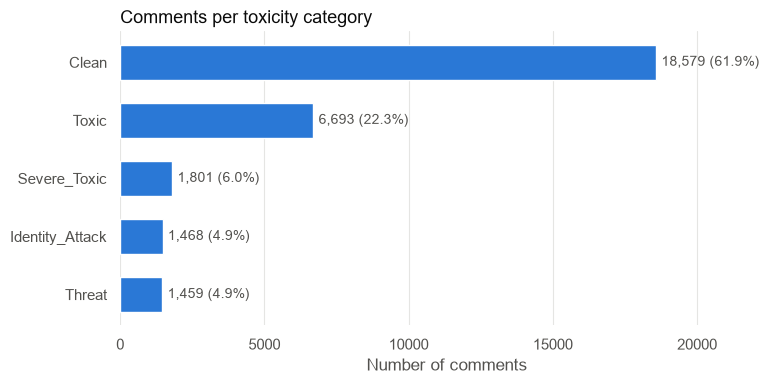

Saved to outputs/plots/target_distribution.png


In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
order = label_counts.sort_values().index  # largest bar at the top
bars = ax.barh(order, label_counts[order], color="#2a78d6", height=0.6)

for bar, label in zip(bars, order):
    ax.text(
        bar.get_width() + label_counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{label_counts[label]:,} ({label_dist.at[label, 'percent']:.1f}%)",
        va="center", fontsize=10, color="#52514e",
    )

ax.set_title("Comments per toxicity category", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Number of comments", color="#52514e")
ax.set_xlim(0, label_counts.max() * 1.22)
ax.tick_params(colors="#52514e")
ax.grid(axis="x", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
sns.despine(left=True, bottom=True)

plt.tight_layout()
fig.savefig(PLOTS_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to outputs/plots/target_distribution.png")

In [27]:
imbalance_ratio = label_counts.max() / label_counts.min()
print(f"Largest class : {label_counts.idxmax()} ({label_counts.max():,})")
print(f"Smallest class: {label_counts.idxmin()} ({label_counts.min():,})")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.1f}")

Largest class : Clean (18,579)
Smallest class: Threat (1,459)
Imbalance ratio (largest / smallest): 12.7


**Class imbalance.** The classes are not equally common, as the ratio above shows. A model can
reach a fairly high accuracy just by predicting the majority class most of the time, so in Task 5
we look beyond accuracy, at **per-class precision, recall, and F1-score** and the confusion matrix.
We use a **stratified** train/test split so every class keeps the same proportion in both sets.

### 2.10 Target encoding strategy

Neural networks work with numbers, not text labels, so the five class names will be turned into
integers. The encoding itself is done in the next task, **after** the train/test split. The plan:

- **Encoder:** scikit-learn `LabelEncoder`, which assigns integers in alphabetical order of the
  class names (for example `Clean → 0`). The encoder is saved so predictions can be turned back
  into class names.
- **Format:** one integer per comment (**not** one-hot vectors), so the matching loss function is
  **`sparse_categorical_crossentropy`**.
- **Output layer:** `Dense(5, activation="softmax")`, one probability per class; the predicted
  class is the one with the highest probability.

### 2.11 Final dataset for modelling

We keep only the columns needed for the next tasks: the ID, the cleaned text (model input), and
the target label.

In [28]:
model_df = df[["Comment_ID", "clean_text", "Toxicity_Label"]].copy()
print("Modelling dataset shape:", model_df.shape)
model_df.head()

Modelling dataset shape: (30000, 3)


,Comment_ID,clean_text,Toxicity_Label
0,COM000001,in this discussion the message expresses a clear opinion about the subject source wording comment for review the mes...,Identity_Attack
1,COM000002,regarding the point raised the message expresses a clear opinion about the subject source wording comment for review...,Clean
2,COM000003,from the information provided the message expresses a clear opinion about the subject source wording comment for rev...,Toxic
3,COM000004,in the current conversation the message expresses a clear opinion about the subject source wording comment for revie...,Clean
4,COM000005,looking at this issue the message expresses a clear opinion about the subject source wording comment for review i re...,Clean


### Task 2 Summary

- The text was cleaned with a reusable, tested function (`src/preprocessing.py`).
- Missing values, empty texts, exact duplicates, and label conflicts were checked, with the counts
  shown in the outputs above.
- The records are built from a small set of distinct core comments (near-duplicates). We keep them
  and treat this as a known limitation when interpreting the test results.
- `Toxicity_Label` is used as the mutually exclusive, multi-class target for the Softmax model, and
  it agrees with the binary label columns.
- The class distribution was saved to `outputs/plots/target_distribution.png` and
  `outputs/reports/target_distribution.csv`.

Next, Task 3 splits the data, encodes the labels, and converts the text into padded sequences.